# Portfolio construction and backtest

In [1]:
import sys

sys.path.insert(0, "../code")
import pandas as pd
from kairos import config

P = config.PATHS
pd.read_csv(P.tables / "summary_metrics.csv", index_col=0)

,AnnReturn,AnnVol,Sharpe,Sortino,MaxDrawdown,Calmar,CVaR5,AnnTurnover,Months
BL_ML_Regime,0.073462,0.074971,0.804431,1.280189,-0.161381,0.455208,-0.041039,2.119223,211.0
BL_ML_Regime_IC,0.073685,0.070034,0.859080,1.363082,-0.131158,0.561804,-0.037527,1.324003,211.0
BL_ML_NoRegime,0.090097,0.093789,0.824118,1.329000,-0.226869,0.397134,-0.055002,1.857493,211.0
BL_ML_Raw_Regime,0.071332,0.079092,0.741192,1.139063,-0.171608,0.415668,-0.048684,4.053207,211.0
BL_HistMean_Regime,0.079595,0.073826,0.893913,1.457713,-0.153128,0.519792,-0.038948,1.342525,211.0
Market_Reference,0.103939,0.097418,0.926883,1.519080,-0.210603,0.493530,-0.055646,0.345936,211.0
Equal_Weight,0.094899,0.112512,0.743854,1.299958,-0.235862,0.402351,-0.058937,0.540171,211.0
Static_60_40,0.103733,0.091176,0.980462,1.595831,-0.205222,0.505469,-0.051941,0.265035,211.0
Inverse_Vol,0.066374,0.071303,0.748663,1.185394,-0.177275,0.374415,-0.041878,0.461058,211.0
MeanVariance_LW,0.059977,0.132818,0.402221,0.616532,-0.369744,0.162211,-0.081104,2.524840,211.0


In [2]:
pd.read_csv(P.tables / "significance.csv")

,strategy,benchmark,diff,ci_low,ci_high,p_value,n
0,BL_ML_Regime,BL_ML_Regime_IC,-0.054649,-0.179136,0.066458,0.385154,211
1,BL_ML_Regime,BL_ML_NoRegime,-0.019687,-0.149175,0.098985,0.766808,211
2,BL_ML_Regime,BL_ML_Raw_Regime,0.063240,-0.100849,0.223162,0.450887,211
3,BL_ML_Regime,BL_HistMean_Regime,-0.089482,-0.149929,-0.039685,0.002749,211
4,BL_ML_Regime,Market_Reference,-0.122452,-0.309727,0.040234,0.172207,211
5,BL_ML_Regime,Equal_Weight,0.060578,-0.154945,0.300881,0.595101,211
6,BL_ML_Regime,Static_60_40,-0.176031,-0.427457,0.029875,0.133967,211
7,BL_ML_Regime,Inverse_Vol,0.055769,-0.198639,0.269870,0.633842,211
8,BL_ML_Regime,MeanVariance_LW,0.402210,0.102408,0.711039,0.012247,211
9,BL_ML_Regime,Regime_60_40,-0.175357,-0.412881,0.030734,0.122469,211


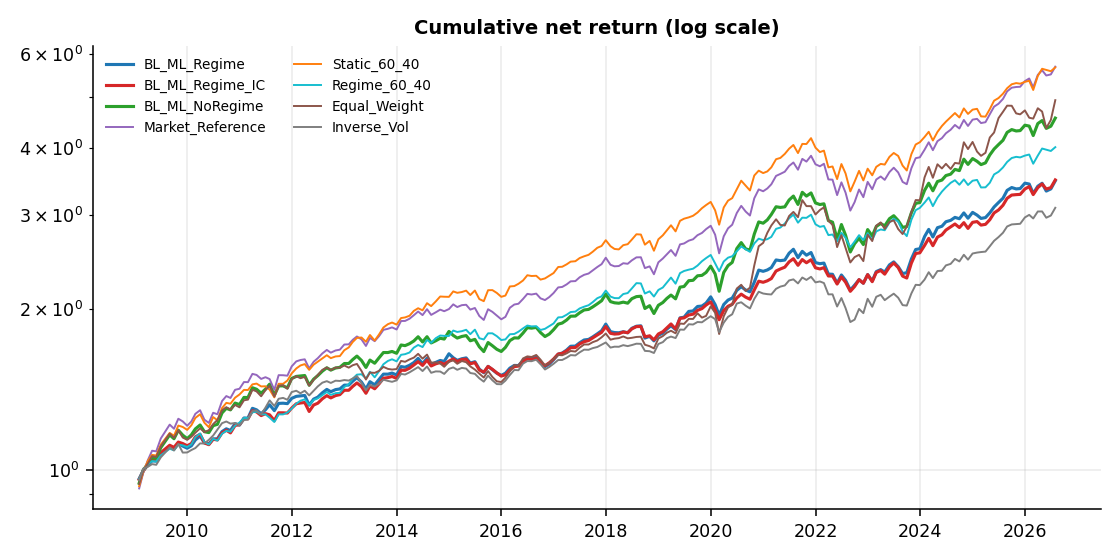

In [3]:
from IPython.display import Image

Image(str(P.figures / "07_cumulative_returns.png"))

In [4]:
pd.read_csv(P.tables / "regime_metrics.csv", index_col=[0, 1])

AnnReturn    AnnVol    Sharpe   Sortino  \
BL_ML_Regime       All        0.073462  0.074971  0.804431  1.280189   
                   Calm       0.067078  0.075885  0.695558  1.105097   
                   Stressed   0.086719  0.073474  1.031061  1.654431   
BL_ML_Regime_IC    All        0.073685  0.070034  0.859080  1.363082   
                   Calm       0.066397  0.070340  0.735674  1.147108   
                   Stressed   0.088841  0.069733  1.110843  1.837725   
BL_ML_NoRegime     All        0.090097  0.093789  0.824118  1.329000   
                   Calm       0.067616  0.075875  0.702348  1.117794   
                   Stressed   0.137864  0.122305  1.037594  1.683364   
BL_ML_Raw_Regime   All        0.071332  0.079092  0.741192  1.139063   
                   Calm       0.071137  0.082929  0.689357  1.067811   
                   Stressed   0.071734  0.071124  0.864932  1.311431   
BL_HistMean_Regime All        0.079595  0.073826  0.893913  1.457713   
                   Calm       0.073200  0.074377  0.786033  1.277304   
                   Stressed   0.092876  0.073092  1.114721  1.839798   
Market_Reference   All        0.103939  0.097418  0.926883  1.519080   
                   Calm       0.075984  0.074823  0.816134  1.288680   
                   Stressed   0.163775  0.131488  1.146670  1.913965   
Equal_Weight       All        0.094899  0.112512  0.743854  1.299958   
                   Calm       0.057008  0.094981  0.471497  0.806763   
                   Stressed   0.177207  0.140178  1.169160  2.055228   
Static_60_40       All        0.103733  0.091176  0.980462  1.595831   
                   Calm       0.080392  0.070113  0.922228  1.435876   
                   Stressed   0.153368  0.123258  1.140569  1.906032   
Inverse_Vol        All        0.066374  0.071303  0.748663  1.185394   
                   Calm       0.055294  0.060090  0.674895  1.087121   
                   Stressed   0.089546  0.090259  0.885495  1.381842   
MeanVariance_LW    All        0.059977  0.132818  0.402221  0.616532   
                   Calm       0.038848  0.114899  0.255875  0.366346   
                   Stressed   0.104822  0.163822  0.627872  1.042592   
Regime_60_40       All        0.082348  0.069463  0.979789  1.551506   
                   Calm       0.079598  0.070123  0.911538  1.415967   
                   Stressed   0.088031  0.068567  1.117040  1.861110   
Regime_Market      All        0.081244  0.074160  0.910349  1.456206   
                   Calm       0.075202  0.074840  0.806140  1.269599   
                   Stressed   0.093785  0.073171  1.124443  1.872131   

                             MaxDrawdown    Calmar     CVaR5  AnnTurnover  \
BL_ML_Regime       All         -0.161381  0.455208 -0.041039     2.119223   
                   Calm        -0.116699  0.574799 -0.038618     2.103572   
                   Stressed    -0.111736  0.776100 -0.042490     2.151434   
BL_ML_Regime_IC    All         -0.131158  0.561804 -0.037527     1.324003   
                   Calm        -0.101792  0.652283 -0.036096     1.100371   
                   Stressed    -0.097145  0.914516 -0.038900     1.784231   
BL_ML_NoRegime     All         -0.226869  0.397134 -0.055002     1.857493   
                   Calm        -0.115859  0.583608 -0.038575     1.597955   
                   Stressed    -0.190520  0.723619 -0.070446     2.391614   
BL_ML_Raw_Regime   All         -0.171608  0.415668 -0.048684     4.053207   
                   Calm        -0.113022  0.629405 -0.047823     4.387814   
                   Stressed    -0.114847  0.624605 -0.046632     3.364596   
BL_HistMean_Regime All         -0.153128  0.519792 -0.038948     1.342525   
                   Calm        -0.109076  0.671089 -0.036517     1.149277   
                   Stressed    -0.109151  0.850894 -0.040609     1.740224   
Market_Reference   All         -0.210603  0.493530 -0.055646     0.345936   
                   Calm        -0.105625  0.719375 -0.0

In [5]:
pd.read_csv(P.tables / "cost_sensitivity.csv", index_col=0)

,0bps,10bps,25bps,50bps
BL_ML_Regime,0.833592,0.804431,0.760695,0.687865
BL_ML_Regime_IC,0.878805,0.859080,0.829457,0.780026
BL_ML_NoRegime,0.844976,0.824118,0.792862,0.740876
BL_ML_Raw_Regime,0.792255,0.741192,0.664387,0.535949
BL_HistMean_Regime,0.912742,0.893913,0.865634,0.818432
Market_Reference,0.930855,0.926883,0.920921,0.910976
Equal_Weight,0.748848,0.743854,0.736358,0.723855
Static_60_40,0.983801,0.980462,0.975448,0.967074
Inverse_Vol,0.755557,0.748663,0.738318,0.721066
MeanVariance_LW,0.421113,0.402221,0.373841,0.326436
